tips:  

if modeling don't work, maybe forgot to preoprocess??  
must normalize and cut the initial part  
to be sure, tart in the middle, where the obscillation has already started  
bc the initial part screws it up  

or it could be a problem with the initial guesses

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/lib/python3/dist-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/usr/lib/python3/dist-packages/traitlets/config/application.py", line 982, in launch_instance
    app.start()
  File "/usr/lib/python3/dist-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start()
  File "/usr/lib/python3/dist-packages/tornado/platform/asyncio.py", line 205, in s

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/lib/python3/dist-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/usr/lib/python3/dist-packages/traitlets/config/application.py", line 982, in launch_instance
    app.start()
  File "/usr/lib/python3/dist-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start()
  File "/usr/lib/python3/dist-packages/tornado/platform/asyncio.py", line 205, in s

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



2025-05-01 13:31:52.492015: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-05-01 13:31:52.492546: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-01 13:31:52.495269: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-01 13:31:52.502579: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1746099112.514210   16707 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1746099112.51

## Get data

1: single pendulum, not damped  
6: single pendulum, damped

2: in phase  
3: out of phase

4,5: battimenti

In [2]:
path1 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoloooooooo.txt'

df1 = pd.read_csv(path1, header=None, delim_whitespace=True,
                   names=["t1", "pendulum1", "t2", "pendulum2"])


/tmp/ipykernel_16707/2116520698.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df1 = pd.read_csv(path1, header=None, delim_whitespace=True,


In [3]:
df1.head()

,t1,pendulum1,t2,pendulum2
0,0.025,1023,0.051,473
1,0.076,1023,0.102,472
2,0.126,1023,0.152,472
3,0.178,1023,0.203,472
4,0.228,1022,0.253,472


In [4]:
path2 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendolooo-2.txt'

df2 = pd.read_csv(path2, header=None, delim_whitespace=True,
                   names=["t1", "pendulum1", "t2", "pendulum2"])


/tmp/ipykernel_16707/1964655550.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df2 = pd.read_csv(path2, header=None, delim_whitespace=True,


In [5]:
df2.head()

,t1,pendulum1,t2,pendulum2
0,0.026,265,0.050,331
1,0.076,262,0.101,330
2,0.127,261,0.151,333
3,0.177,261,0.203,331
4,0.228,266,0.254,333


In [6]:
path3 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoliiii-3.txt'

df3 = pd.read_csv(path3, header=None, delim_whitespace=True, comment='#',
                   names=["t1", "pendulum1", "t2", "pendulum2"])


/tmp/ipykernel_16707/3919187044.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df3 = pd.read_csv(path3, header=None, delim_whitespace=True, comment='#',


In [7]:
df3.head()

,t1,pendulum1,t2,pendulum2
0,0.025,684,0.051,245
1,0.076,683,0.101,245
2,0.127,688,0.152,242
3,0.177,683,0.202,247
4,0.228,685,0.254,247


In [8]:
path4 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendolooooo-4.txt'

df4 = pd.read_csv(path4, header=None, delim_whitespace=True, comment='#',
                   names=["t1", "pendulum1", "t2", "pendulum2"])


/tmp/ipykernel_16707/2064854851.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df4 = pd.read_csv(path4, header=None, delim_whitespace=True, comment='#',


In [9]:
df4

,t1,pendulum1,t2,pendulum2
0,0.025,429,0.051,225
1,0.075,430,0.101,226
2,0.127,428,0.152,225
3,0.177,432,0.202,224
4,0.228,429,0.254,226
...,...,...,...,...
3492,177.038,434,177.064,498
3493,177.089,433,177.115,498
3494,177.139,434,177.165,498
3495,177.191,435,177.216,499


In [10]:
path5 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoloooooo-5.txt'

df5 = pd.read_csv(path5, header=None, delim_whitespace=True, comment='#',
                   names=["t1", "pendulum1", "t2", "pendulum2"])


/tmp/ipykernel_16707/2253857442.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df5 = pd.read_csv(path5, header=None, delim_whitespace=True, comment='#',


In [11]:
path6 = '/home/gea/Desktop/Lab 1/pendolo_accoppiato_data/pendoliiiiiiiii.txt'

df6 = pd.read_csv(path6, header=None, delim_whitespace=True, comment='#',
                   names=["t1", "pendulum1", "t2", "pendulum2"])


/tmp/ipykernel_16707/3951449572.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df6 = pd.read_csv(path6, header=None, delim_whitespace=True, comment='#',


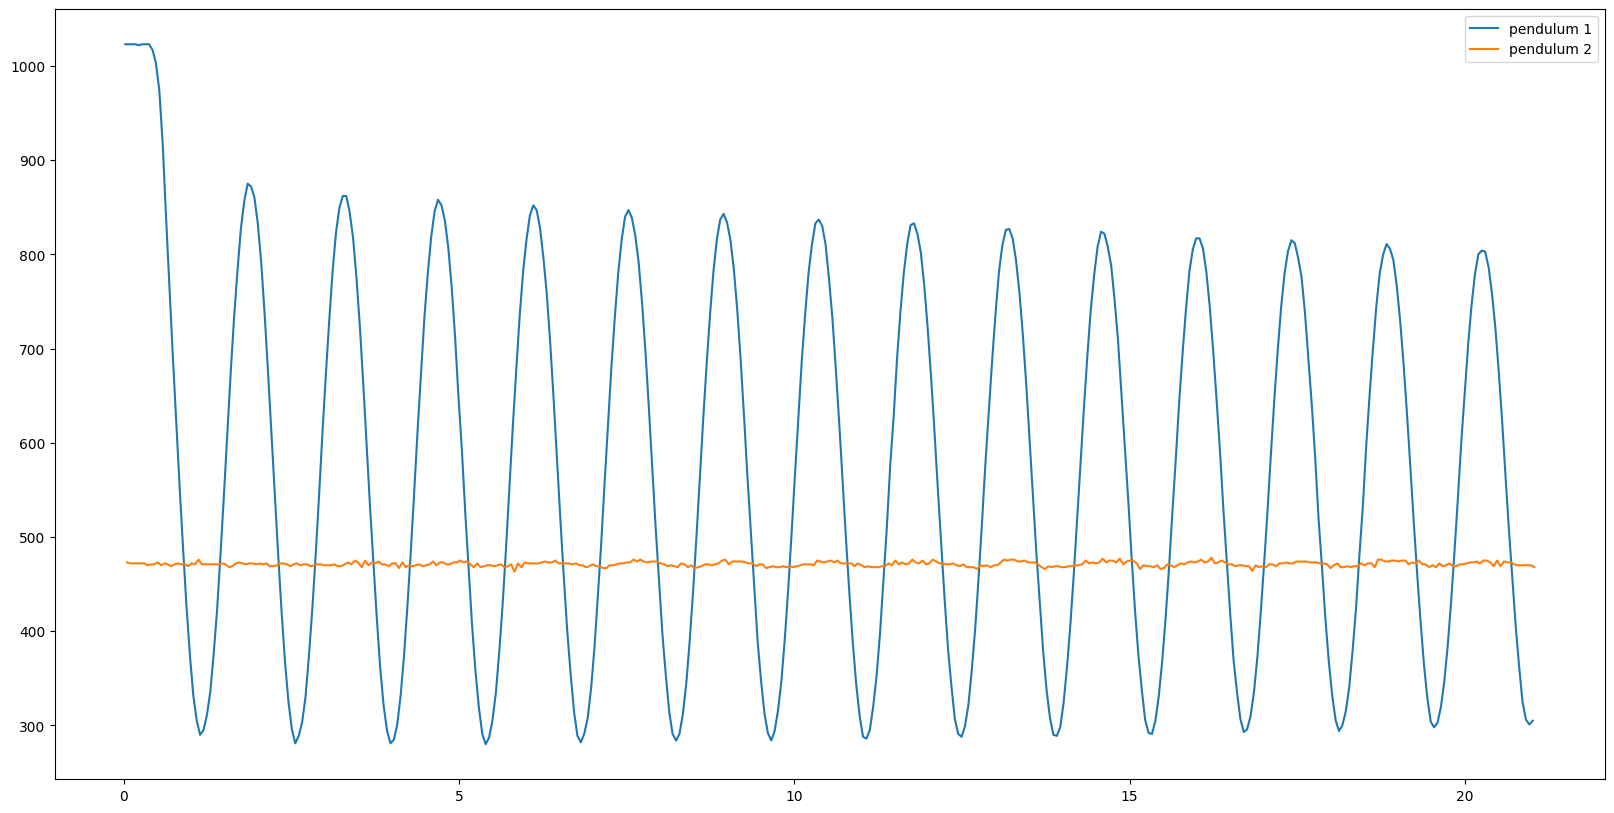

In [12]:
# Check what they are

x1 = df1.t1
x2 = df1.t2

y1 = df1.pendulum1
y2 = df1.pendulum2


plt.figure(figsize=(20,10))
plt.plot(x1,y1, label='pendulum 1')
plt.plot(x2,y2, label='pendulum 2')
plt.legend()

## Ready-made functions

In [13]:
### Get peaks - WORKS FOR BOTH DAMPED AND UNDAMPED

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

def get_peaks(x,y):
    '''Pass it t and theta (timestamp and position)'''

    # === 2. Define model for fitting ===
    def damped_oscillator(x, A, lambda_, omega, phi, offset):
        return A * np.exp(-lambda_ * x) * np.sin(omega * x + phi) + offset

    # === 3. Fit the model ===
    # guess = [1.0, 0.1, 2*np.pi, 0.0, 0.0]
    params, _ = curve_fit(damped_oscillator, x, y) # p0=guess
    # A, lambda_, omega, phi, offset = params     HERE ARE THE PARAMS

    # === 4. Evaluate fitted model on dense grid and find peaks ===
    x_dense = np.linspace(x.min(), x.max(), 5000)
    y_fit = damped_oscillator(x_dense, *params)

    peak_indices, _ = find_peaks(y_fit)
    x_peaks = x_dense[peak_indices]
    y_peaks = y_fit[peak_indices]

    plt.figure(figsize=(10,5))
    plt.plot(x, y, '.', label='Data')
    plt.plot(x_dense, y_fit, label='Fitted model')
    plt.plot(x_peaks, y_peaks, 'ro', label='Detected peaks')
    plt.title('Pendolo semplice')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return x_peaks, y_peaks, params

get_peaks has the offset parameter in the function it's trying to fit, so can fit the function even if the obscillation are not centered at amplitude 0  
however, normalizing before would make the convergence easier, and can pass 0 as an initial extimate for offset, so maybe do it?  

**Extimate initial param**

plot the points and see from the graph  

$A$: semi-amplitude of the first obscillation  

$\omega$: count number of obscillations in some time interval, $T=\frac{time \, interval}{number \, obscillations}$ and $\omega = \frac{2 \pi}{T}$ 

$\phi$: at $t=0$, if it's at extremity it's $\pm\frac{\pi}{2}$ (- if bottom, è is top) ???  

$\lambda$: time coord when ampltude has become a third, extimate by eye  

$offset$: mean, horizontal line at the center of obscillations  
if normalized before, it's 0  

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

def double_pendulums(t1, y1, t2, y2):
    '''Handles independent timestamps for two pendulums: t1/y1 and t2/y2'''

    # === Model for fitting ===
    def damped_oscillator(t, A, lambda_, omega, phi, offset):
        return A * np.exp(-lambda_ * t) * np.sin(omega * t + phi) + offset

    #guess = [1.0, 0.05, 4.5, 0.0, 0.0]
    guess = [(np.max(y1)-np.min(y1))/2, 0.01, 4.5, 0.0, np.mean(y1)]

    # === Fit for pendulum 1 ===
    params1, _ = curve_fit(damped_oscillator, t1, y1, p0=guess)
    A1, lambda1, omega1, phi1, offset1 = params1
    t1_dense = np.linspace(t1.min(), t1.max(), 5000)
    y1_fit = damped_oscillator(t1_dense, *params1)
    x_peaks1 = t1_dense[find_peaks(y1_fit)[0]]
    y_peaks1 = y1_fit[find_peaks(y1_fit)[0]]

    # === Fit for pendulum 2 ===
    params2, _ = curve_fit(damped_oscillator, t2, y2, p0=guess)
    A2, lambda2, omega2, phi2, offset2 = params2
    t2_dense = np.linspace(t2.min(), t2.max(), 5000)
    y2_fit = damped_oscillator(t2_dense, *params2)
    x_peaks2 = t2_dense[find_peaks(y2_fit)[0]]
    y_peaks2 = y2_fit[find_peaks(y2_fit)[0]]

    # === Plotting ===
    fig = plt.figure(figsize=(20, 10))
    ax1, ax2 = fig.subplots(2, 1, sharex=False, gridspec_kw=dict(hspace=0.05))

    ax1.plot(t1, y1, '.', label='Pendulum 1 data')
    ax1.plot(t1_dense, y1_fit, label='Fit 1')
    ax1.plot(x_peaks1, y_peaks1, 'ro', label='Peaks 1')
    ax1.set_ylabel('θ₁(t)')
    ax1.grid(True)
    ax1.legend()

    ax2.plot(t2, y2, '.', label='Pendulum 2 data')
    ax2.plot(t2_dense, y2_fit, label='Fit 2')
    ax2.plot(x_peaks2, y_peaks2, 'ro', label='Peaks 2')
    ax2.set_xlabel('Time')
    ax2.set_ylabel('θ₂(t)')
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.show()

    # === Optional: Phase difference at t=0 ===
    delta_phi = (phi2 - phi1) % (2*np.pi)
    print(f"Phase difference φ₂ - φ₁ = {delta_phi:.3f} rad")

    return x_peaks1, y_peaks1, params1, x_peaks2, y_peaks2, params2

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks
from scipy.fft import fft, fftfreq

def analyze_beats(t, y):


    t = np.asarray(t)
    y = np.asarray(y)


    dt = t[1] - t[0]
    fs = 1 / dt
    N = len(t)

    # === 1. FFT to find dominant frequencies ===
    yf = fft(y)
    freqs = fftfreq(N, d=dt)
    idx = np.argsort(np.abs(yf[:N//2]))[::-1]  # Sort by magnitude

    # Take the two strongest positive frequencies
    dominant_freqs = freqs[idx[:2]]
    dominant_freqs = np.abs(dominant_freqs)
    omega1, omega2 = 2 * np.pi * dominant_freqs

    # === 2. Estimate ω_m and ω_b ===
    omega_m = (omega1 + omega2) / 2
    omega_b = abs(omega1 - omega2) / 2

    # === 3. Construct carrier and envelope ===
    carrier = np.cos(omega_m * t)
    envelope = np.abs(hilbert(y))  # analytical signal gives envelope

    # === 4. Plot ===
    plt.figure(figsize=(10, 6))
    plt.plot(t, y, label='Segnale')
    plt.plot(t, envelope, 'r--', label='Modulante') #envelope
    plt.plot(t, -envelope, 'r--')
    plt.plot(t, carrier, 'g:', label='Portante') #carrier
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.title('Battimenti')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"Estimated omega1 = {omega1:.3f} rad/s")
    print(f"Estimated omega2 = {omega2:.3f} rad/s")
    print(f"=> omega_m (carrier) = {omega_m:.3f} rad/s")
    print(f"=> omega_b (envelope) = {omega_b:.3f} rad/s")

    return omega_m, omega_b

## Simple pendulum, undamped

### Find peaks

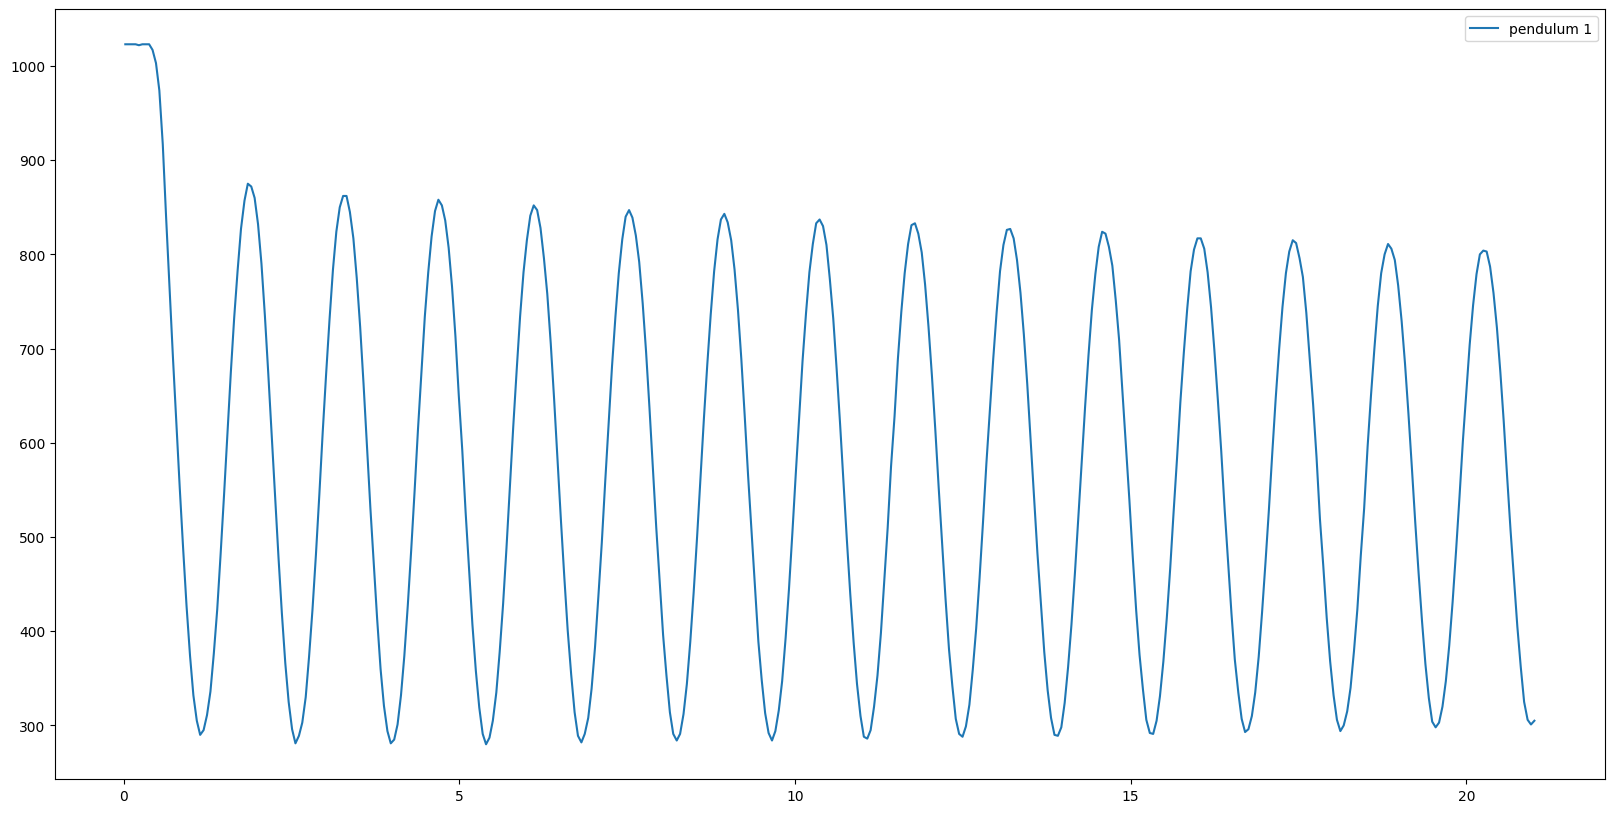

In [16]:
x = df1.t1
y = df1.pendulum1

# check that it's pendulum1 moving, and not pendulum2

plt.figure(figsize=(20,10))
plt.plot(x,y, label='pendulum 1')
plt.legend()

/home/gea/.local/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


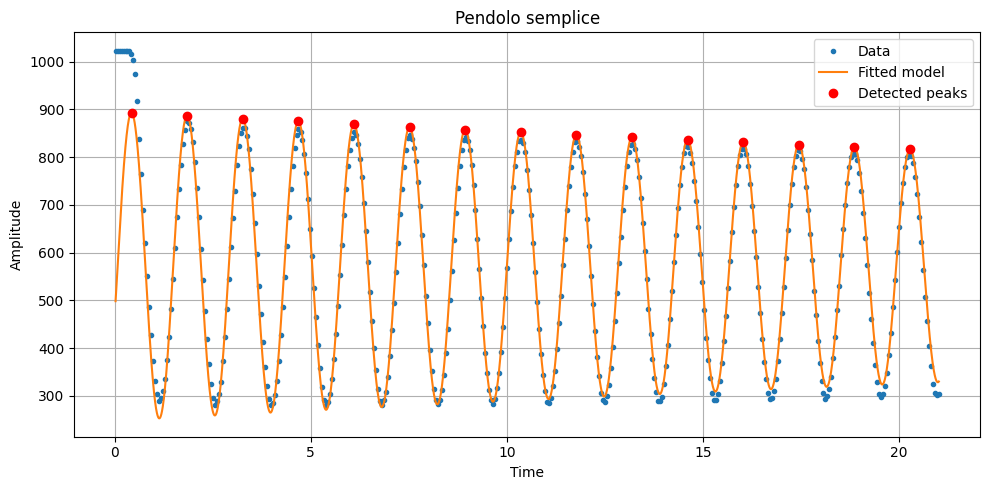

In [17]:
t_simple, theta_simple, params1= get_peaks(x,y)

### Find period and pulsation

In [18]:
print(f'Omega = {params1[2]}')

Omega = 4.431995422993228


In [19]:
# Or by hand, if only have peaks (so also find uncertainty)

periods = np.array([t_simple[i+1] - t_simple[i] for i in range(len(t_simple)-1)]) 
period=np.mean(periods) 
omegas = 2*np.pi/periods

omega = np.mean(omegas)
err_omega = np.std(omegas)

print(f'omega = {omega:.3f} +{err_omega:.3f}')

omega = 4.433 +0.006


## Simple damped pendulum

### Find peaks

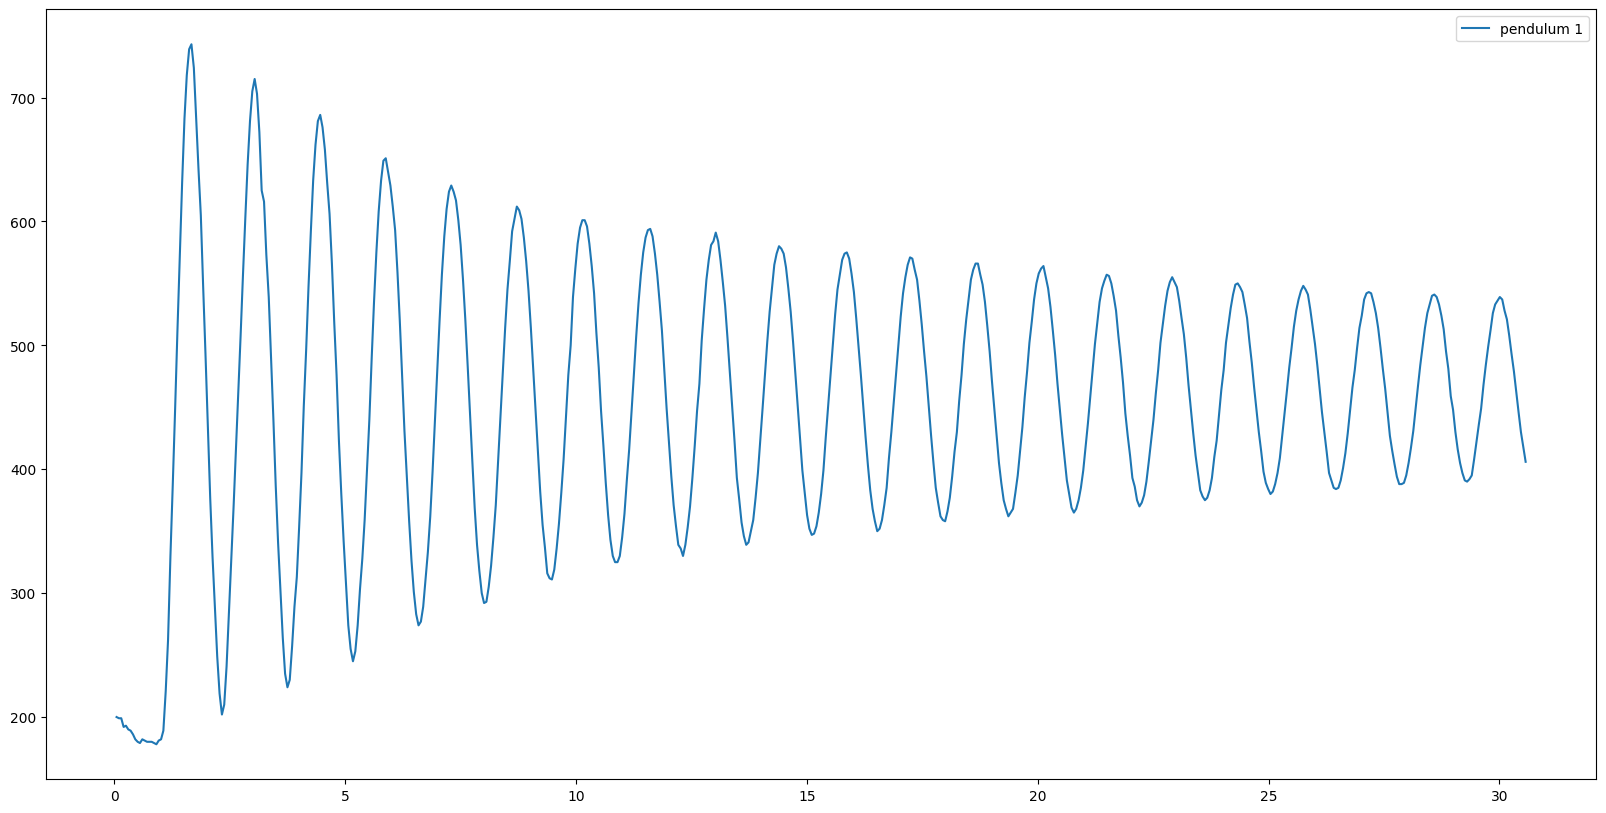

In [20]:
x = df6.t2
y = df6.pendulum2

# check that it's pendulum1 moving, and not pendulum2

plt.figure(figsize=(20,10))
plt.plot(x,y, label='pendulum 1')
plt.legend()

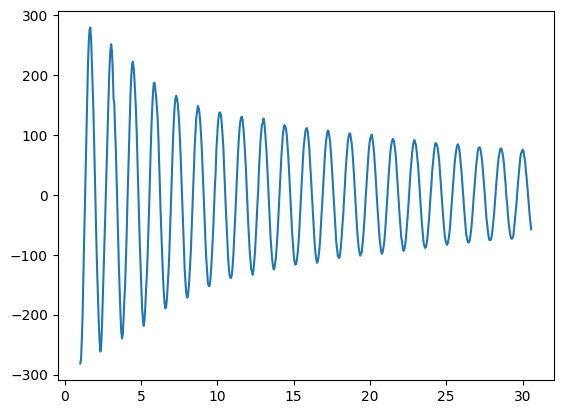

In [21]:
# PREPROCESSING

# MAKE IT START FROM t=5, delete initial static part, else can't fit it

mask = x >= 1
x_mask = x[mask]
y_mask = y[mask]


# NORMALIZE !!!  (need to take the mean, so only after taking away the initial steady part)

signal = y_mask - np.mean(y_mask)

plt.plot(x_mask, signal)

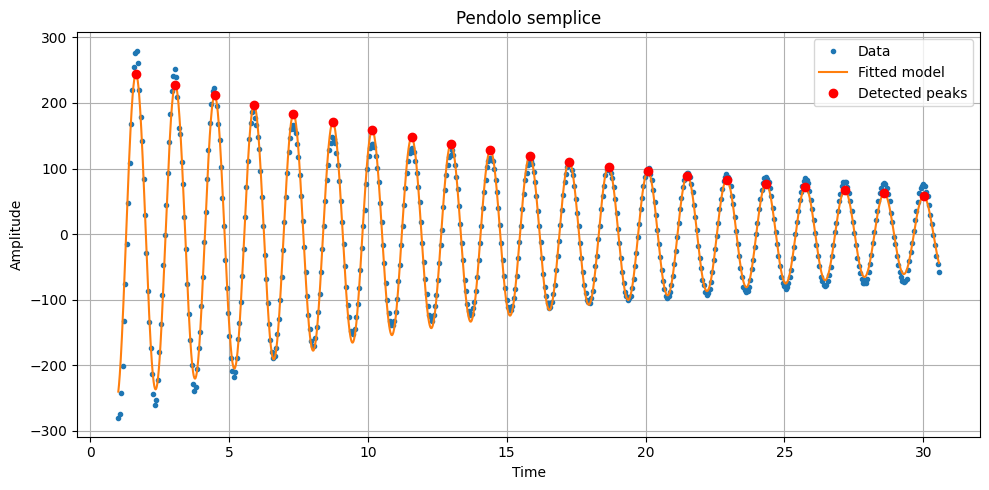

In [22]:
t_damped, theta_damped, params= get_peaks(x_mask, signal)

In [23]:
print(f'Omega = {params1[2]}')

Omega = 4.431995422993228


### Extimate decay time

In [24]:
print(f'Tau = {1/params[1]}')

Tau = 19.753201158608416


teorically could have gotten it from previous fit as well, but this is logarithmic scale?  

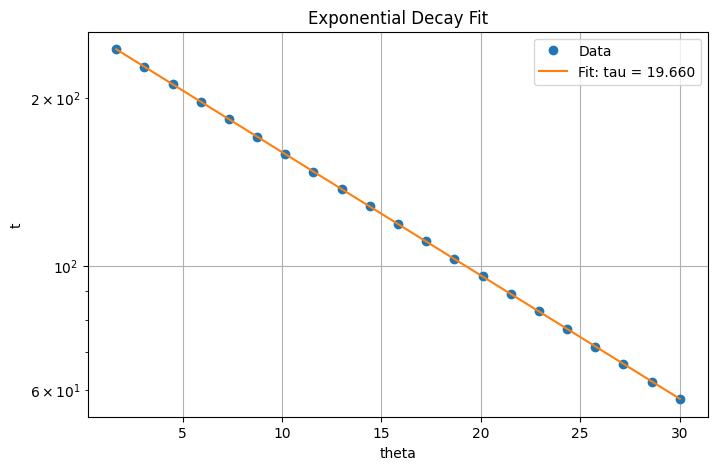

Estimated tau: 19.659517861591734


In [25]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


t = t_damped        # Time values
theta = theta_damped    # Corresponding theta values

def exponential_decay(t, theta0, tau):
    return theta0 * np.exp(-t / tau)

# guess = [theta[0], 1.0]
params, cov = curve_fit(exponential_decay, t, theta)  # po =g guess
theta0_fit, tau_fit = params


# Plot it
t_dense = np.linspace(t.min(), t.max(), 1000)
theta_fit = exponential_decay(t_dense, *params)

plt.figure(figsize=(8, 5))
plt.plot(t, theta, 'o', label='Data')
plt.plot(t_dense, theta_fit, label=f'Fit: tau = {tau_fit:.3f}')
plt.xlabel('theta')
plt.ylabel('t')
plt.title('Exponential Decay Fit')
plt.legend()
plt.yscale('log')

plt.grid(True)
plt.show()


print(f"Estimated tau: {tau_fit}")

### Check period

In [26]:
period_damped = np.array([t_damped[i+1] - t_damped[i] for i in range(len(t_damped)-1)])  

In [27]:
print(f'Undamped period: {np.mean(period)} \n' 
      f'Damped period: {np.mean(period_damped)}')

Undamped period: 1.4175056296973683 
Damped period: 1.4182365873174636


## Obscillations phase

### In phase

In [28]:
# Get data

x1 = df2.t1
x2 = df2.t2

y1 = df2.pendulum1
y2 = df2.pendulum2

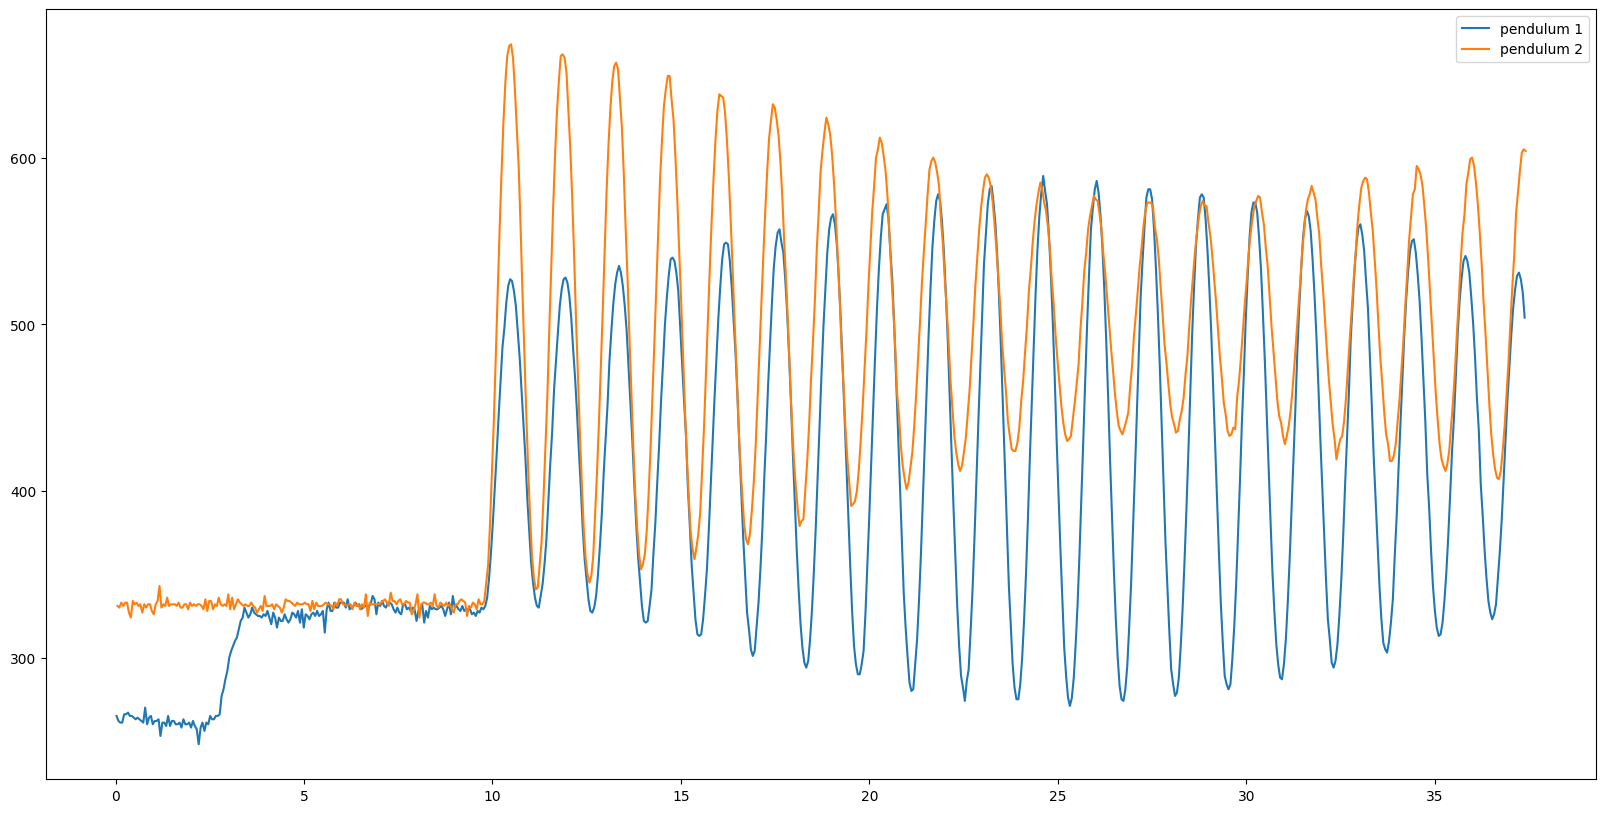

In [29]:
# Plot to check at what point to cut

plt.figure(figsize=(20,10))
plt.plot(x1,y1, label='pendulum 1')
plt.plot(x2,y2, label='pendulum 2')
plt.legend()

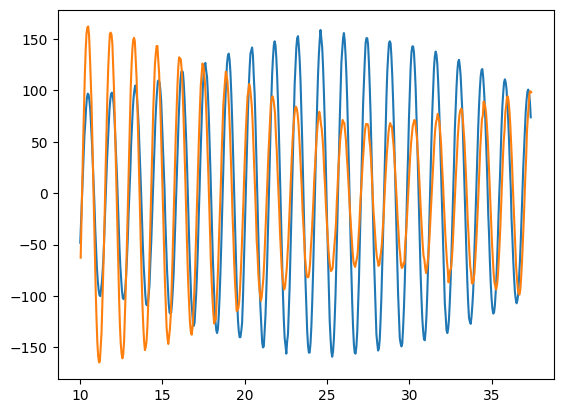

In [30]:
# PREPROCESSING

# MAKE IT START FROM t=5, delete initial static part, else can't fit it

mask1 = x1 >= 10
x1_mask = x1[mask1]
y1_mask = y1[mask1]

mask2 = x2 >= 10
x2_mask = x2[mask2]
y2_mask = y2[mask2]


# NORMALIZE !!!  (need to take the mean, so only after taking away the initial steady part)

signal_a = y1_mask - np.mean(y1_mask)
signal_b = y2_mask - np.mean(y2_mask)

plt.plot(x1_mask, signal_a, label='pendulum 1')
plt.plot(x2_mask, signal_b, label='pendulum 2')


/tmp/ipykernel_16707/747157495.py:17: OptimizeWarning: Covariance of the parameters could not be estimated
  params1, _ = curve_fit(damped_oscillator, t1, y1, p0=guess)
/tmp/ipykernel_16707/747157495.py:25: OptimizeWarning: Covariance of the parameters could not be estimated
  params2, _ = curve_fit(damped_oscillator, t2, y2, p0=guess)
/tmp/ipykernel_16707/747157495.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


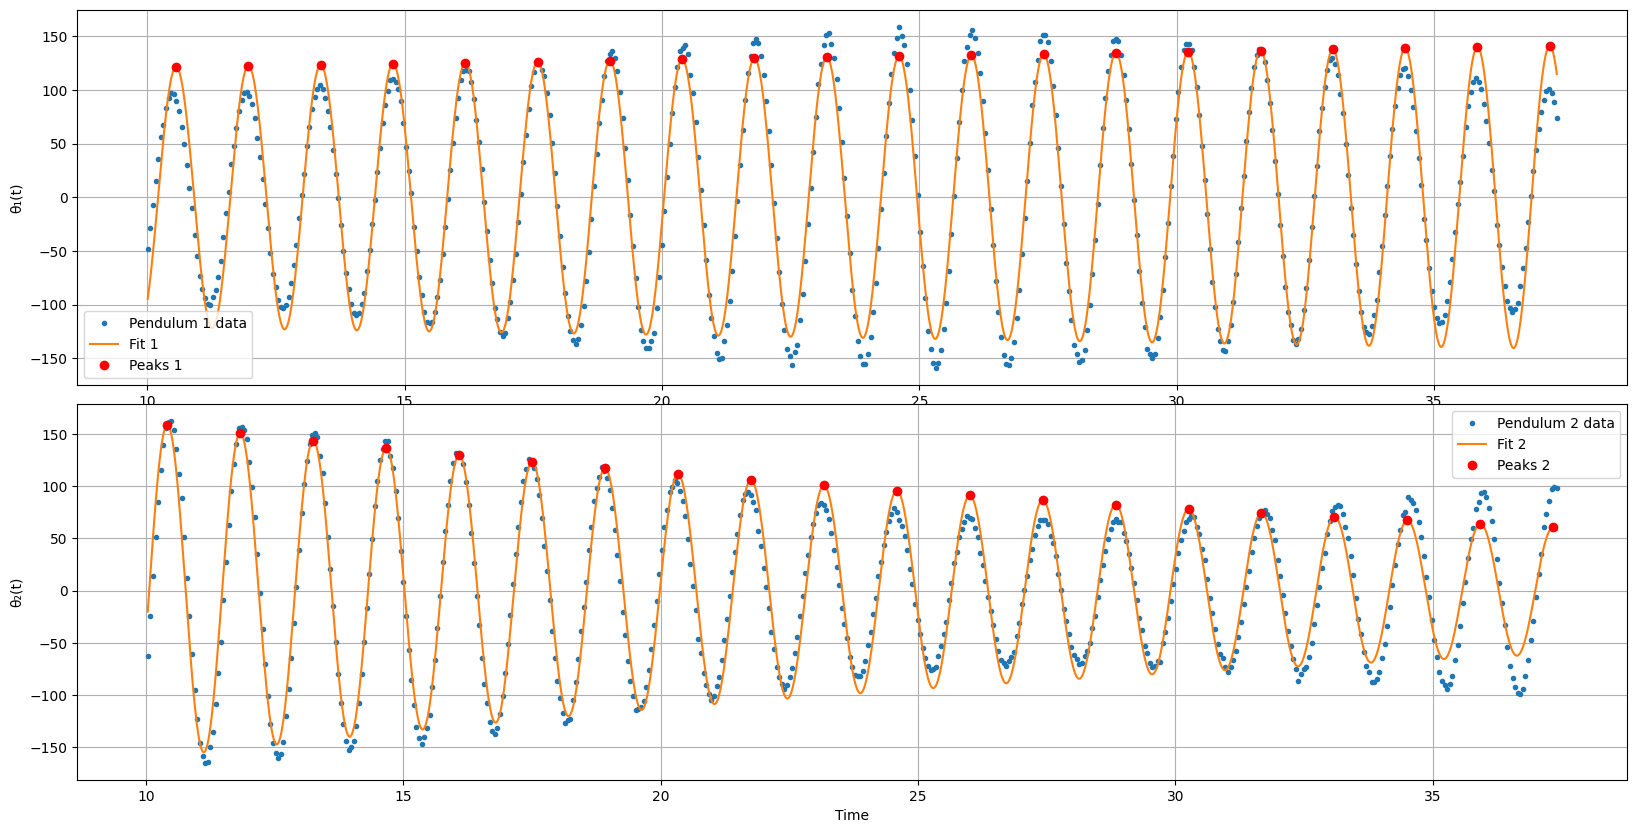

Phase difference φ₂ - φ₁ = 1.062 rad


In [31]:
t1, theta1, param1, t2, theta2, param2 = double_pendulums(x1_mask, signal_a, x2_mask, signal_b)

In [32]:
print(f'omega_1 = {param1[2]} \n',
      f'omega_2 = {param2[2]}')

omega_1 = 4.474187921548813 
 omega_2 = 4.433866981575764


### Out of phase

In [33]:
# Get data

x1 = df3.t1
x2 = df3.t2

y1 = df3.pendulum1
y2 = df3.pendulum2

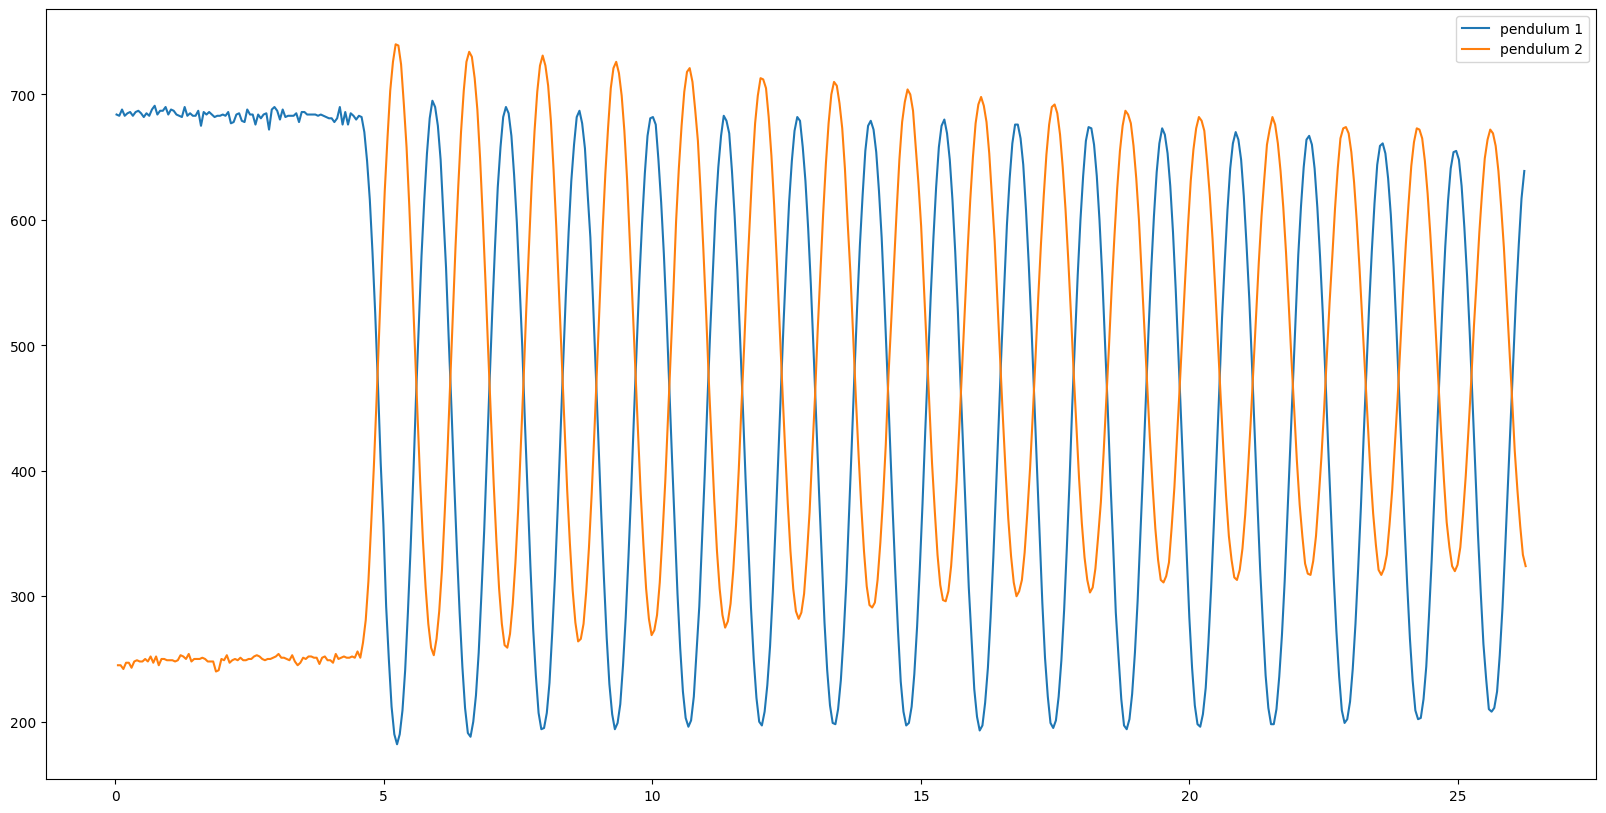

In [34]:
# Plot to check at what point to cut

plt.figure(figsize=(20,10))
plt.plot(x1,y1, label='pendulum 1')
plt.plot(x2,y2, label='pendulum 2')
plt.legend()

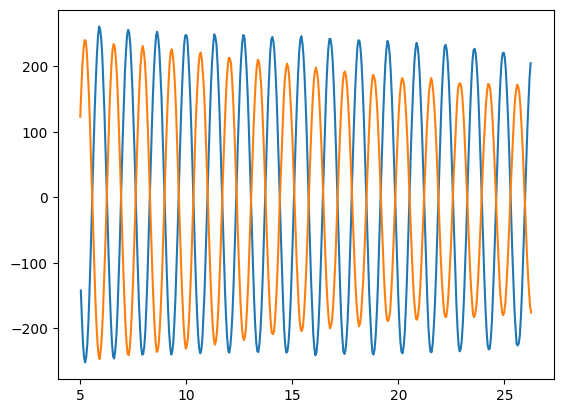

In [35]:
# PREPROCESSING

# MAKE IT START FROM t=5, delete initial static part, else can't fit it

mask1 = x1 >= 5
x1_mask = x1[mask1]
y1_mask = y1[mask1]

mask2 = x2 >= 5
x2_mask = x2[mask2]
y2_mask = y2[mask2]


# NORMALIZE !!!  

signal_a = y1_mask - np.mean(y1_mask)
signal_b = y2_mask - np.mean(y2_mask)

plt.plot(x1_mask, signal_a, label='pendulum 1')
plt.plot(x2_mask, signal_b, label='pendulum 2')


/tmp/ipykernel_16707/747157495.py:17: OptimizeWarning: Covariance of the parameters could not be estimated
  params1, _ = curve_fit(damped_oscillator, t1, y1, p0=guess)
/tmp/ipykernel_16707/747157495.py:25: OptimizeWarning: Covariance of the parameters could not be estimated
  params2, _ = curve_fit(damped_oscillator, t2, y2, p0=guess)
/tmp/ipykernel_16707/747157495.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


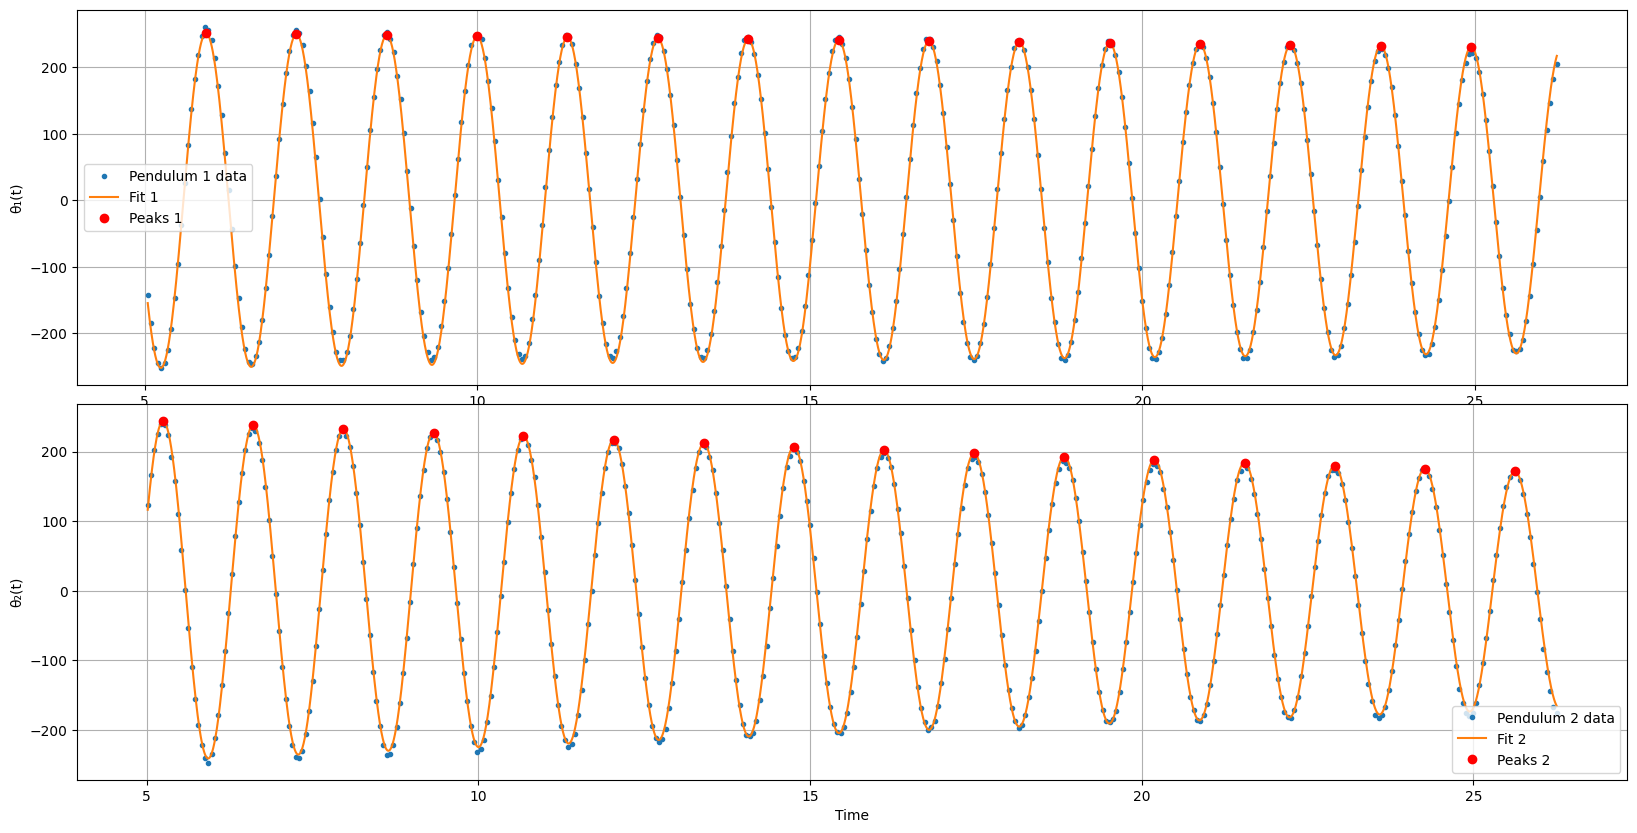

Phase difference φ₂ - φ₁ = 3.089 rad


In [36]:
t1, theta1, param1, t2, theta2, param2 = double_pendulums(x1_mask, signal_a, x2_mask, signal_b)

In [37]:
print(f'omega_1 = {param1[2]} \n',
      f'omega_2 = {param2[2]}')

omega_1 = 4.623725029281428 
 omega_2 = 4.625571443407299


## Battimenti

In [38]:
# Get data

x1 = df4.t1
x2 = df4.t2

y1 = df4.pendulum1
y2 = df4.pendulum2

signal_a = y1 - np.mean(y1)


In [39]:

x1 = np.asarray(x1)
signal_a = np.asarray(signal_a)


only need to plot one pendulum, if want can plot 2, but whatever  

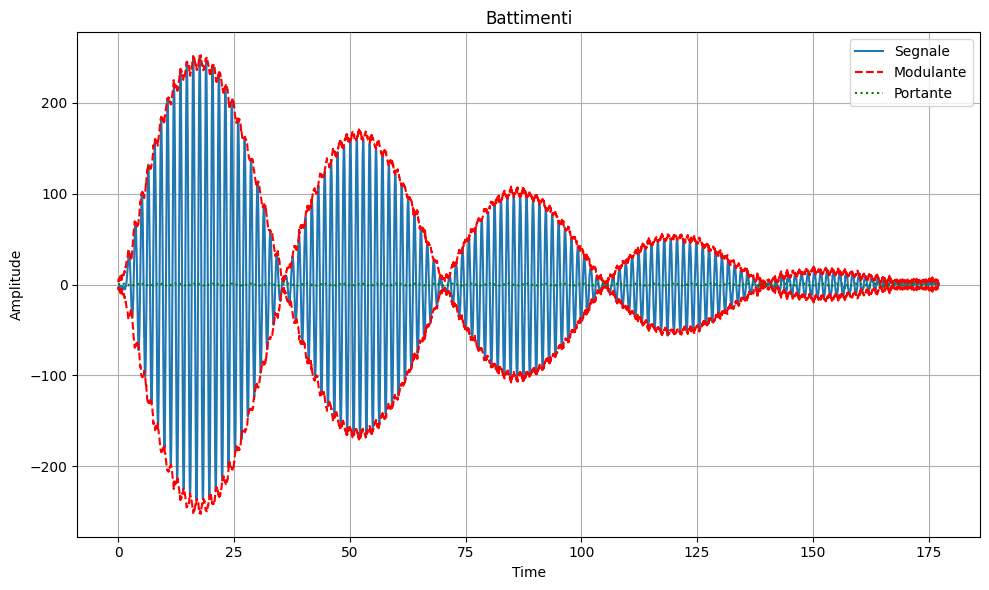

Estimated omega1 = 4.528 rad/s
Estimated omega2 = 4.707 rad/s
=> omega_m (carrier) = 4.618 rad/s
=> omega_b (envelope) = 0.090 rad/s


In [40]:
a,b = analyze_beats(x1,signal_a)